# 04 · Customer Analytics

Repeat purchasing, cohorts, value concentration, RFM and ML segments.

> Data: Olist Brazilian E-Commerce public dataset (BRL). All narrative under charts is generated from the computed statistics.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)
from src.analytics import eda
om, items, cm, daily = eda.load()

def show(f):
    if f.figure: display(Image(filename=str(ROOT / f.figure)))
    display(Markdown(f"**Business interpretation – {f.title}:** {f.interpretation}"))


## Repeat purchasing

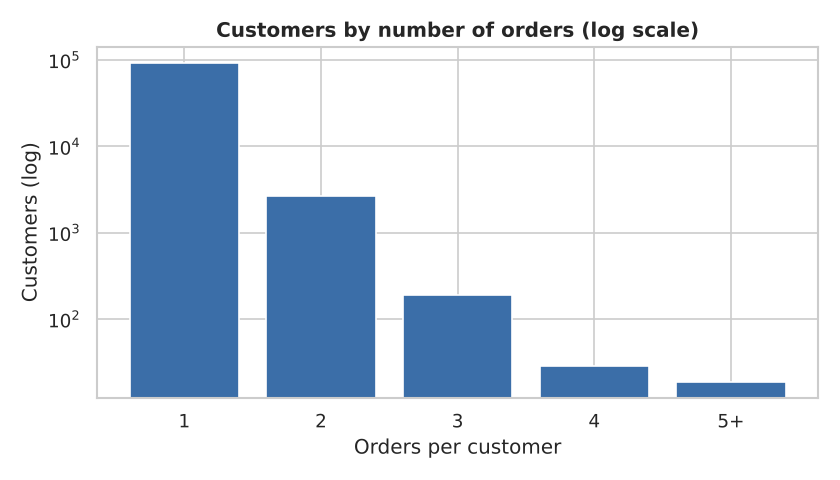

**Business interpretation – Repeat purchasing:** Only 3.04% of 94,983 customers ordered more than once; they contribute 5.7% of revenue and are worth 1.9× a one-time buyer. Retention is the single largest structural weakness of the business.

In [2]:
show(eda.customer_repeat(cm))

## Cohort retention

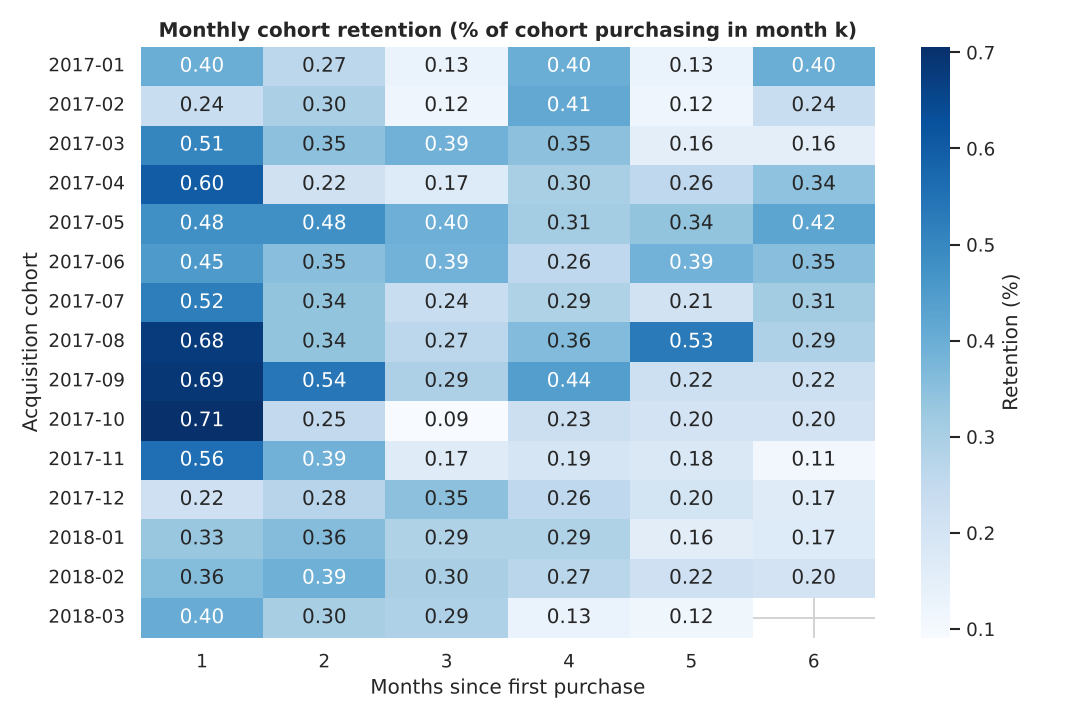

**Business interpretation – Cohort retention:** Average month-1 retention is 0.48% and stays below 0.5% from month 2 onward – cohorts do not build a recurring base. Every month's revenue must be re-acquired.

In [3]:
show(eda.customer_cohorts(om))

## Customer value / CLV

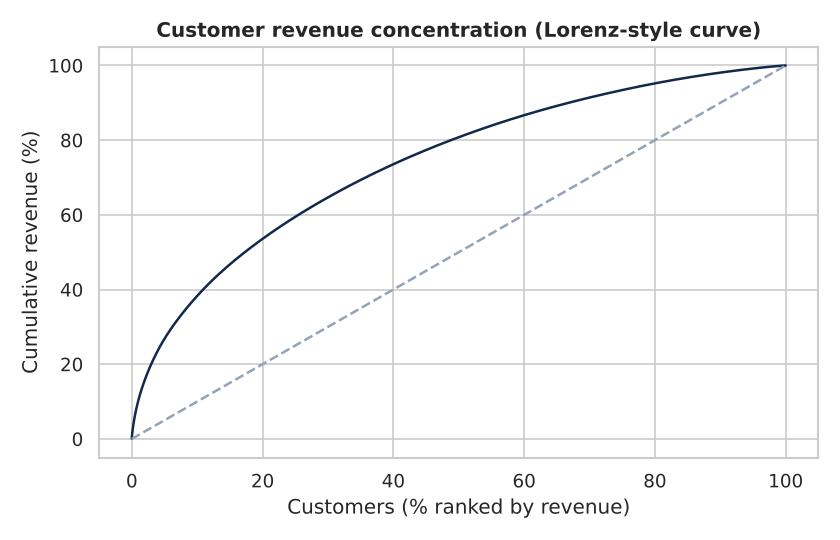

**Business interpretation – Customer lifetime value:** The top 20% of customers generate 54% of revenue. Historical CLV ≈ AOV R$ 160.24 × 1.034 orders = R$ 165.67; because frequency is ~1, CLV is essentially the first basket – raising frequency is the main CLV lever.

In [4]:
show(eda.customer_clv(cm))

## RFM & K-Means segments (from `ml/customer_segmentation`)

In [5]:
pd.read_csv('reports/ml/segmentation_cluster_profile.csv')[['cluster_name','customers','customer_share_pct','revenue_share_pct','recency_median','frequency_mean','monetary_median','recommended_strategy']]

,cluster_name,customers,customer_share_pct,revenue_share_pct,recency_median,frequency_mean,monetary_median,recommended_strategy
0,Recent One-Time Buyers,24029,25.30,26.01,65.0,1.000000,111.17,Drive the 2nd order: post-delivery cross-sell ...
1,Lapsed One-Time Buyers,68067,71.66,68.33,284.0,1.000000,103.86,Low-cost automated win-back (email/push) on th...
2,Loyal Repeat Buyers,2887,3.04,5.66,207.0,2.113959,225.55,"Protect: VIP perks, early access, referral pro..."


In [6]:
pd.read_csv('reports/ml/segmentation_rfm_profile.csv')

,rfm_segment,customers,avg_recency,avg_monetary,revenue,strategy
0,At Risk - High Value,13989,400.937379,309.104528,4324063.24,Personal win-back offer.
1,Champions,1241,94.876712,321.273683,398700.64,Reward and retain; ask for reviews/referrals.
2,Hibernating,22968,402.174460,72.766681,1671305.14,Low-cost automated reactivation only.
3,Loyal - Lapsing,1646,327.396112,298.611525,491514.57,Re-engage loyal buyers before they churn.
4,Needs Attention,18387,226.244521,152.039860,2795556.90,Time-limited incentive to return.
5,New High-Value,14646,97.688857,303.077063,4438866.66,Onboard and drive the second order.
6,New Low-Value,22106,95.647969,73.080606,1615519.88,Nurture with discovery content.


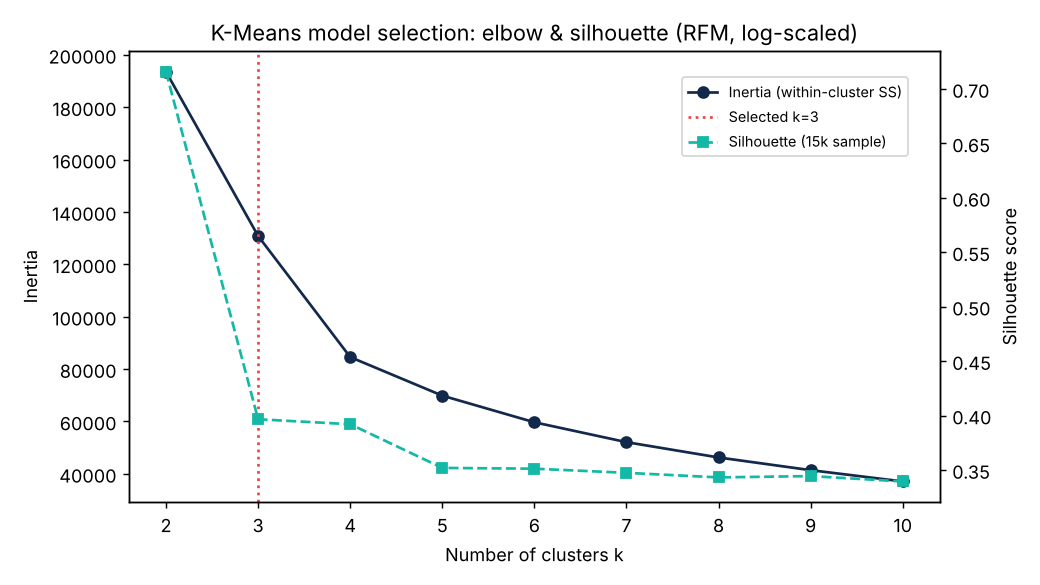

In [7]:
display(Image(filename=str(ROOT / 'reports/figures/ml/segmentation_elbow_silhouette.png')))